In [10]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import os
import seaborn as sns
from pathlib import Path

In [9]:
# Set style for professional charts
plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs("outputs/figures", exist_ok=True)

In [ ]:
root = Path.cwd().resolve()


if not (root / "data" / "raw" / "astra_dataset.csv").exists():
    root = root.parent

project_root = root
csv_path = project_root / "data" / "raw" / "astra_dataset.csv"

### 1. load data

In [12]:
csv_path = "data/raw/astra_dataset.csv"
df = pd.read_csv(csv_path)

print("--- 1. INITIAL DATA OVERVIEW ---")
print(f"Total Samples: {df.shape[0]}, Total Columns: {df.shape[1]}")
print("")
print(df.head(4))

--- 1. INITIAL DATA OVERVIEW ---
Total Samples: 2800, Total Columns: 301

          0         1         2         3         4         5         6  \
0 -0.213732  1.094772  0.213732  0.881040  0.055336  0.881040 -0.103060   
1  0.009050  0.926483  0.009050  0.935533  0.141882  0.935533  0.292815   
2 -0.042993  0.055202  0.042993  0.012209  0.072580  0.012209  0.102167   
3  0.297952 -0.422853  0.297952 -0.124901  0.250017  0.124901  0.797987   

          7         8         9  ...       291       292       293       294  \
0 -0.505674  0.103060 -0.130309  ...  0.262658  0.163970  0.262658  1.160101   
1 -0.908754  0.292815 -0.881975  ... -0.515887 -0.818275  0.515887 -0.732758   
2  0.001850  0.102167  0.015909  ...  0.725703  0.010566  0.725703  0.740302   
3  0.342794  0.797987  0.560687  ... -0.755513 -0.842288  0.755513 -1.039191   

        295       296       297       298       299  label  
0  0.674610  1.160101  1.611877  0.451776  1.611877      0  
1  0.630854  0.732758  0.74

In [13]:
print("\n--- 2. COLUMN NAMES ---")
print(df.columns.tolist()[:10], "... (truncated)")


--- 2. COLUMN NAMES ---
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'] ... (truncated)


### --- STEP 2: DATA CLEANING & INTEGRITY CHECK ---

In [14]:
# missing value
missing_values_count = df.isnull().sum().sum()
print(f"Total missing/ nan values: {missing_values_count}")
print("")

# duplicate 
duplicate_count = df.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_count}")
print("")

# non numerical faetures
non_numeric_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Non-numeric columns found: {non_numeric_cols if non_numeric_cols else 'None (All columns are numeric)'}")
print("")

# descriptive stats of columns and labels
print("\nTarget label unique values & counts:")
print(df['label'].value_counts().sort_index())

Total missing/ nan values: 0

Total Duplicate Rows: 0

Non-numeric columns found: None (All columns are numeric)


Target label unique values & counts:
label
0    700
1    700
2    700
3    700
Name: count, dtype: int64


In [15]:
label_col = 'label' if 'label' in df.columns else df.columns[-1]
class_counts = df[label_col].value_counts().sort_index()

class_names = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}
print("\n--- 3. CLASS DISTRIBUTION ---")
for cls_id, count in class_counts.items():
    name = class_names.get(int(cls_id), f"Class {cls_id}")
    print(f"{name} (ID {cls_id}): {count} samples")


--- 3. CLASS DISTRIBUTION ---
Bird (ID 0): 700 samples
Drone (ID 1): 700 samples
Aircraft (ID 2): 700 samples
Stealth UAV (ID 3): 700 samples


### --- STEP 3: NUMERICAL FEATURE ANALYSIS (WAVEFORM VISUALIZATION) ---

In [ ]:

feature_cols = [str(i) for i in range(300)]
X_3d = df[feature_cols].values.reshape(-1, 100, 3)
y = df['label'].values

class_names = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}

for cls_id, name in class_names.items():
    cls_data = X_3d[y == cls_id]
    # Feature index 1 is Velocity (Gradient of signal / frequency shift)
    vel_std = cls_data[:, :, 1].std()
    mean_amp = cls_data[:, :, 0].mean()
    print(f"{name} -> Mean Amplitude: {mean_amp:.4f} | Velocity Fluctuation (Std): {vel_std:.4f}")

Bird -> Mean Amplitude: 0.0445 | Velocity Fluctuation (Std): 0.4741
Drone -> Mean Amplitude: 0.0164 | Velocity Fluctuation (Std): 0.6455
Aircraft -> Mean Amplitude: 0.3504 | Velocity Fluctuation (Std): 0.0365
Stealth UAV -> Mean Amplitude: 0.0024 | Velocity Fluctuation (Std): 0.3717


/tmp/ipykernel_117649/3368087962.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='class_name', data=df, palette='viridis', order=class_names_map.values())


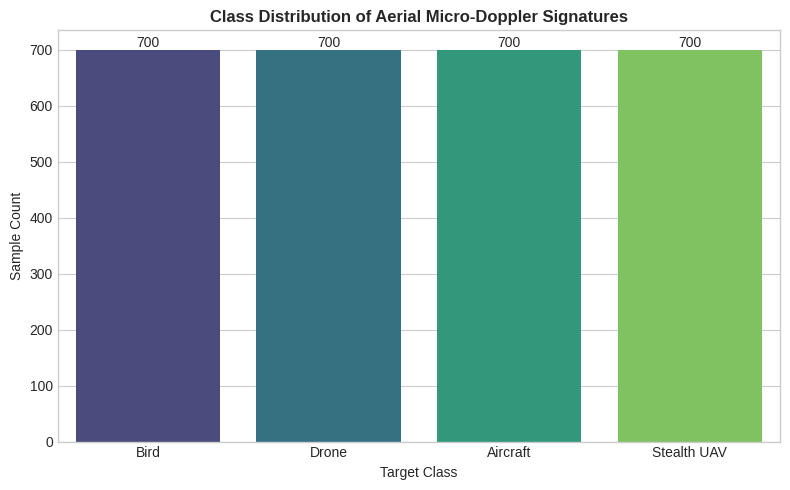

[Saved] Class distribution bar plot -> outputs/figures/class_distribution.png


In [16]:
class_names_map = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}
df['class_name'] = df['label'].map(class_names_map)

plt.figure(figsize=(8, 5))
ax = sns.countplot(x='class_name', data=df, palette='viridis', order=class_names_map.values())
plt.title("Class Distribution of Aerial Micro-Doppler Signatures", fontsize=12, fontweight='bold')
plt.xlabel("Target Class", fontsize=10)
plt.ylabel("Sample Count", fontsize=10)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.savefig("outputs/figures/class_distribution.png", dpi=300)
plt.show()
print("[Saved] Class distribution bar plot -> outputs/figures/class_distribution.png")

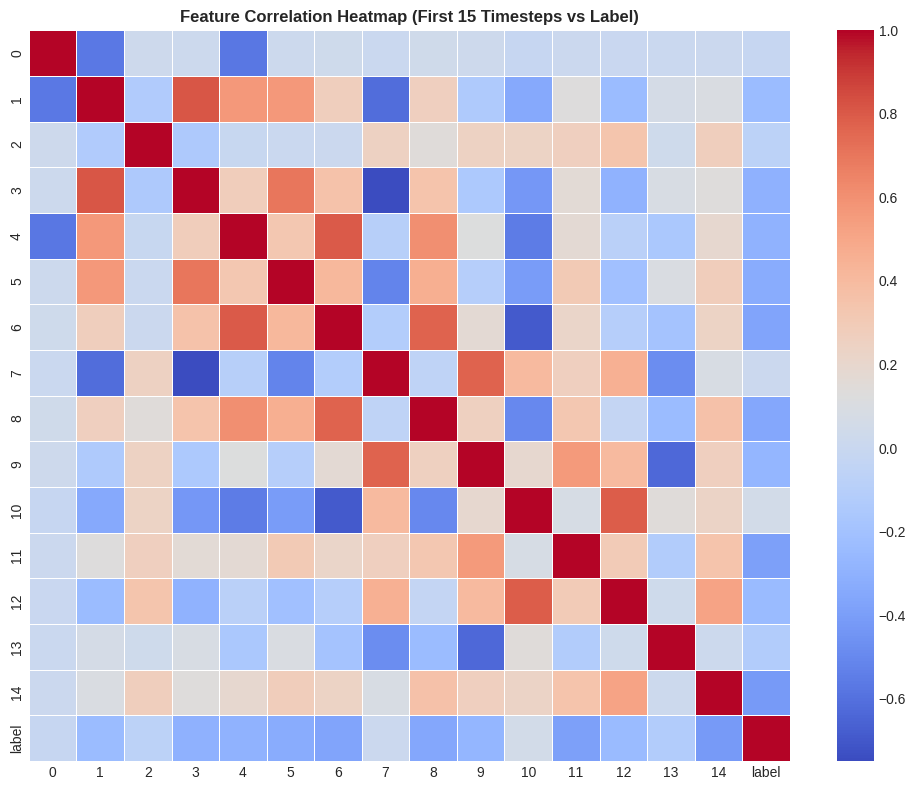

[Saved] Correlation heatmap -> outputs/figures/correlation_heatmap.png


In [17]:
# --- CORRELATION HEATMAP ---


feature_cols = [c for c in df.columns if c != 'label' and c != 'class_name']
sample_cols = feature_cols[:15] + ['label'] # Taking first 15 timesteps + label for readability

plt.figure(figsize=(10, 8))
corr_matrix = df[sample_cols].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False, fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap (First 15 Timesteps vs Label)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("outputs/figures/correlation_heatmap.png", dpi=300)
plt.show()
print("[Saved] Correlation heatmap -> outputs/figures/correlation_heatmap.png")

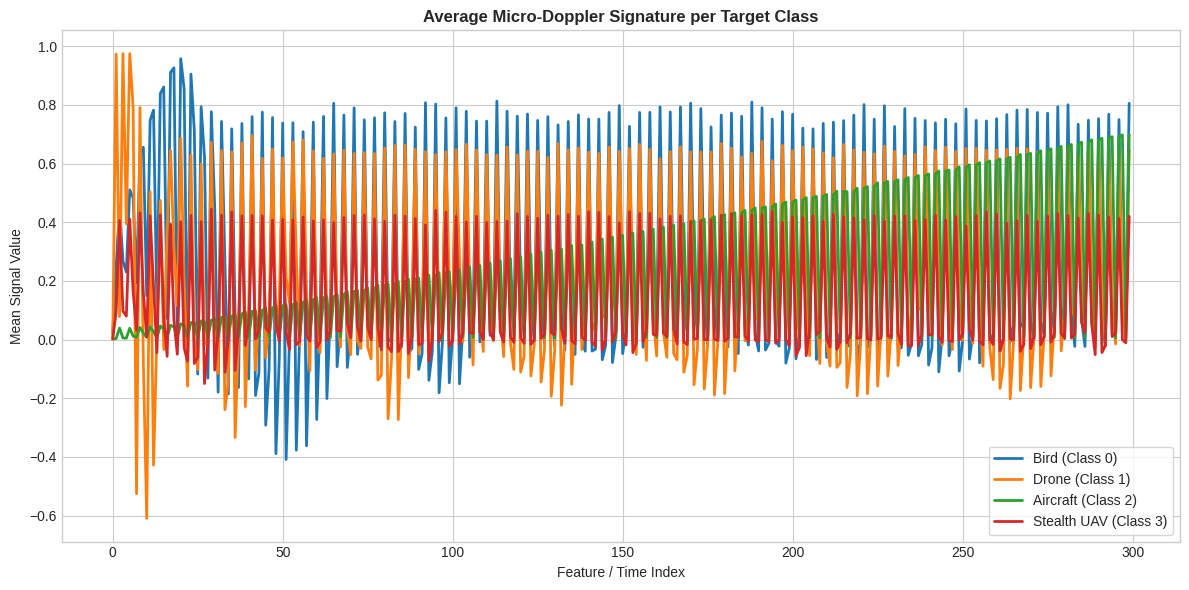

Waveform plot generated successfully without type errors!


In [18]:
# --- CORRECTED STEP 3 PLOT ---


class_names = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}

# Ensure we ONLY pick numeric feature columns (exclude 'label' and any text columns like 'class_name')
feature_cols = [col for col in df.columns if col not in ['label', 'class_name']]

plt.figure(figsize=(12, 6))

for label_id, name in class_names.items():
    # Filter rows for each class and compute the mean across numeric features
    class_data = df[df['label'] == label_id][feature_cols]
    mean_signature = class_data.mean(axis=0).values
    
    plt.plot(mean_signature, label=f"{name} (Class {label_id})", linewidth=2)

plt.title("Average Micro-Doppler Signature per Target Class", fontsize=12, fontweight='bold')
plt.xlabel("Feature / Time Index", fontsize=10)
plt.ylabel("Mean Signal Value", fontsize=10)
plt.legend(frameon=True)
plt.tight_layout()

# Save figure for GitHub repo and slides
plt.savefig("outputs/figures/micro_doppler_waveforms.png", dpi=300)
plt.show()

print("Waveform plot generated successfully without type errors!")

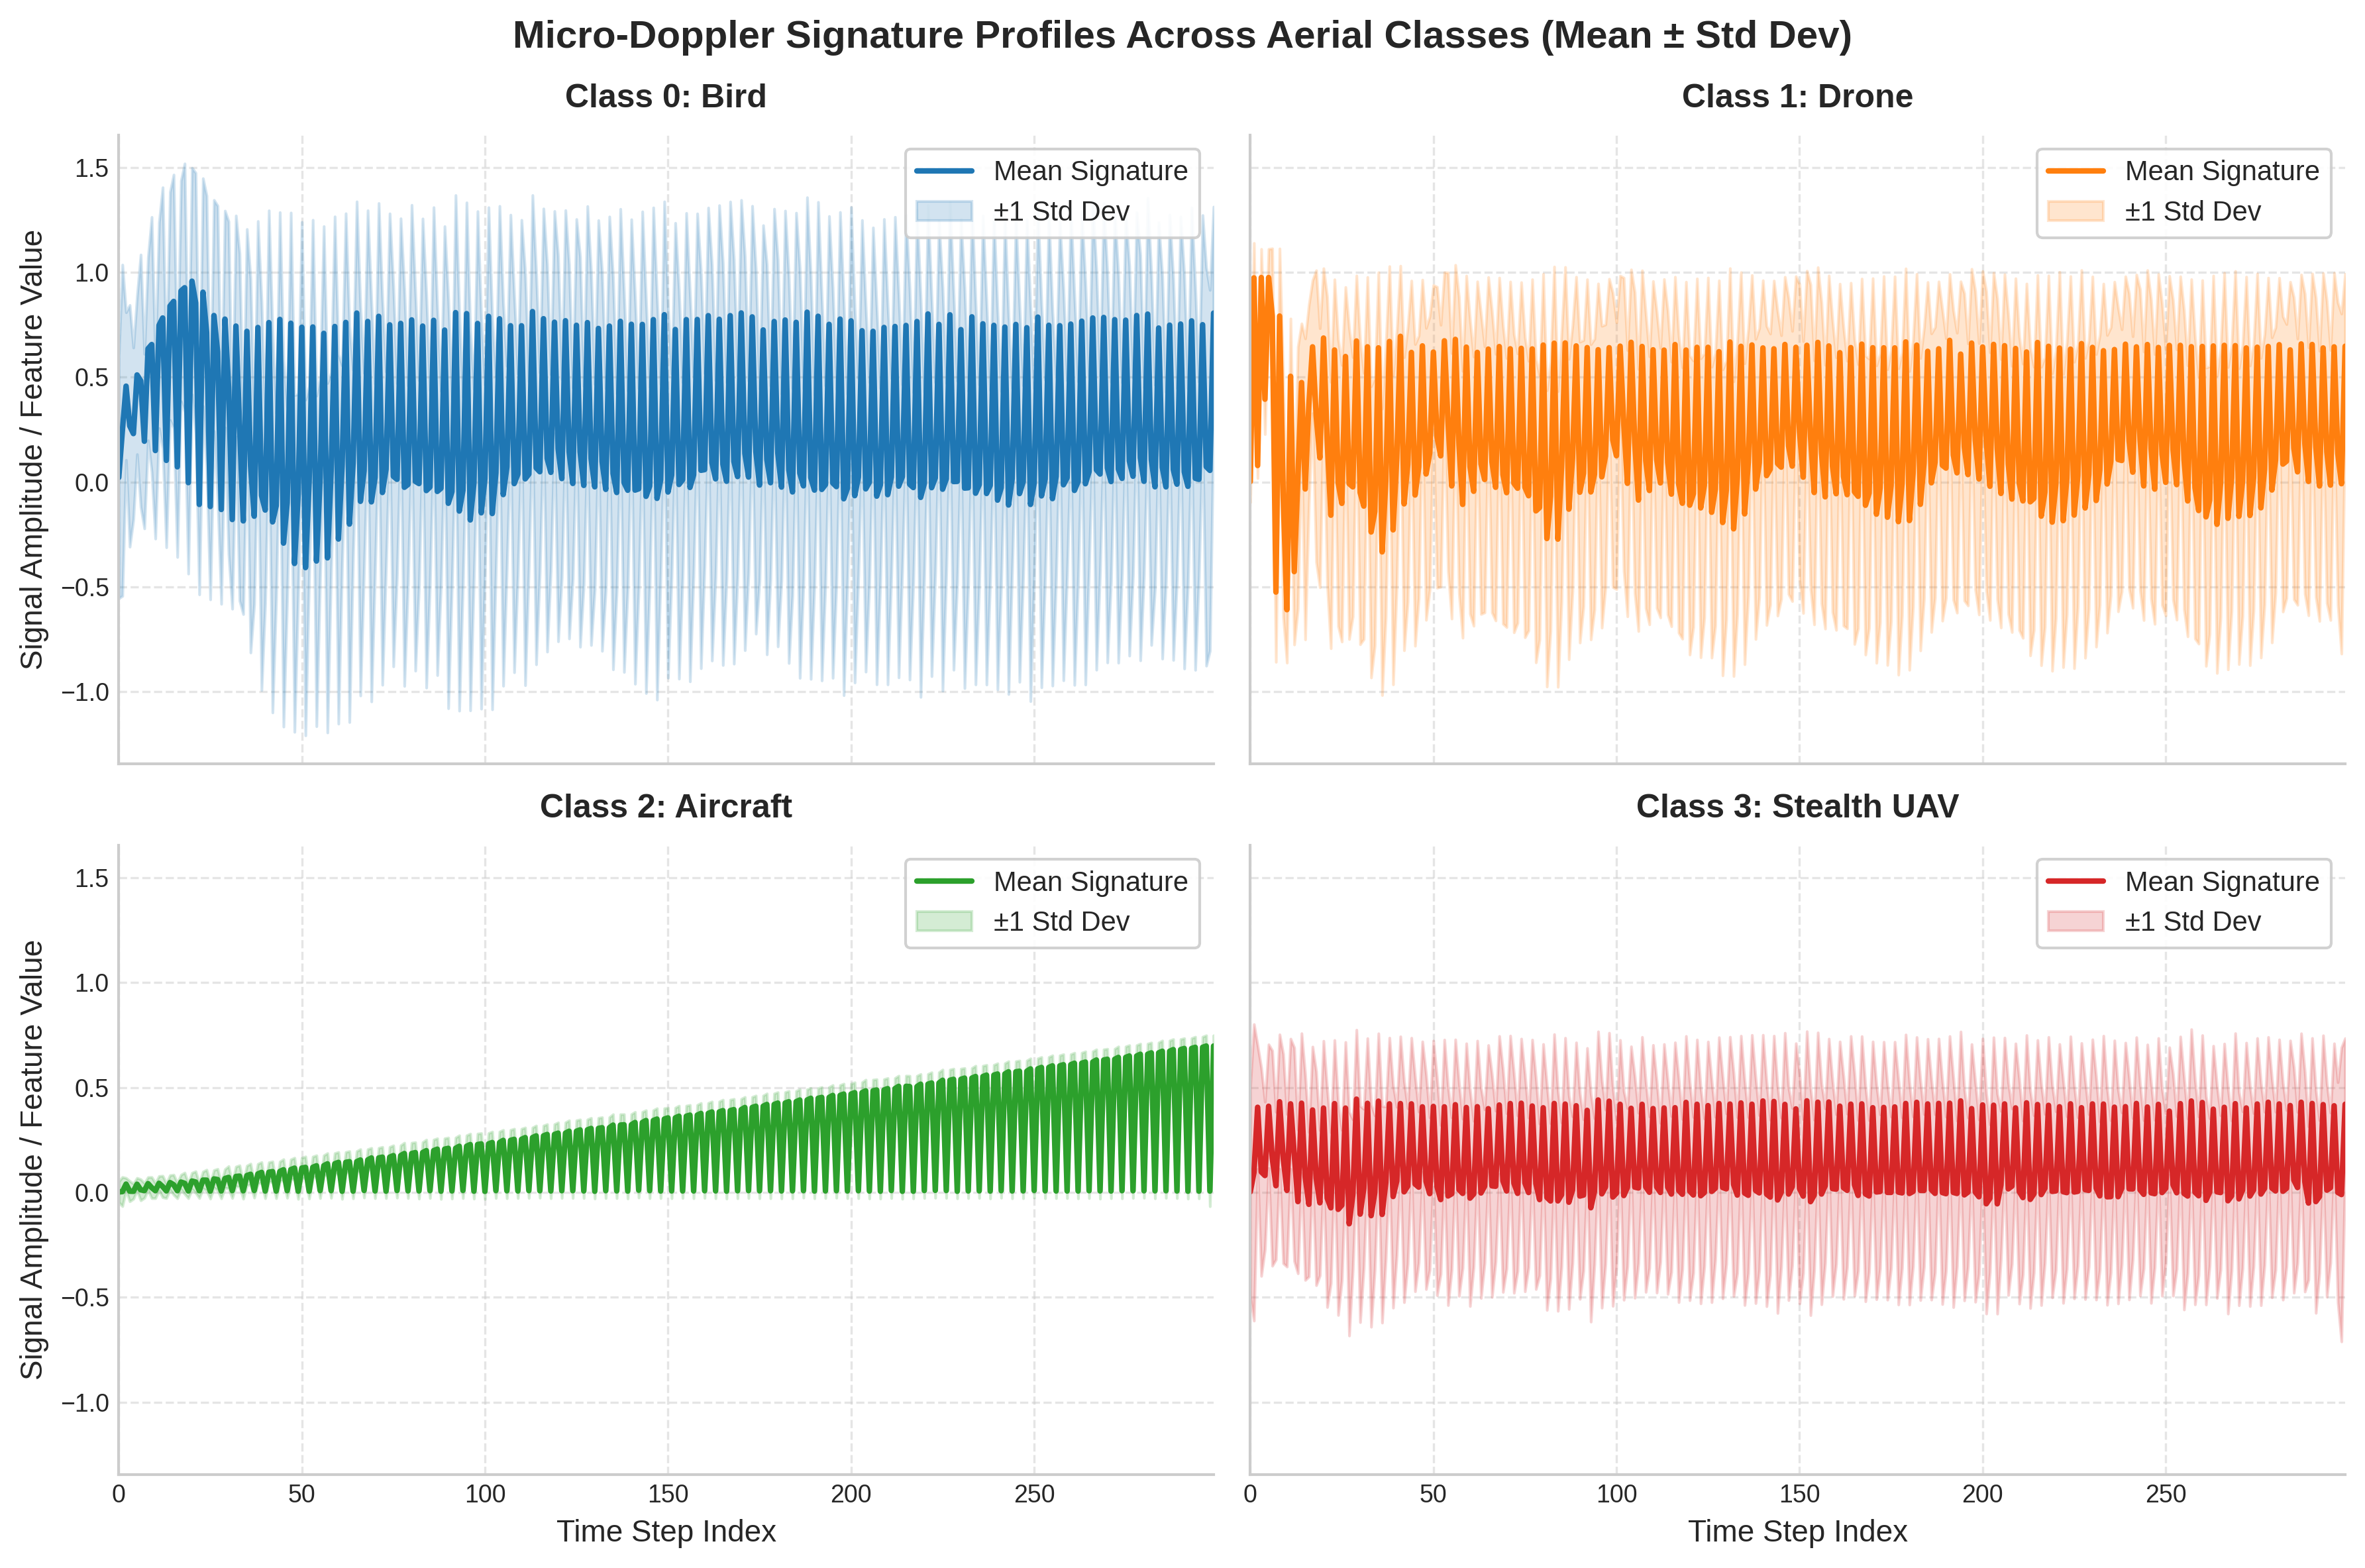

Publication-grade figure successfully saved to outputs/figures/micro_doppler_conference_style.png


In [23]:
os.makedirs("outputs/figures", exist_ok=True)

# 1. Configure publication-quality matplotlib settings
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False
})

class_names = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}

# FIX: Explicitly exclude 'label', 'class_name', or any non-numeric columns
feature_cols = [col for col in df.columns if col not in ['label', 'class_name'] and pd.api.types.is_numeric_dtype(df[col])]
time_steps = np.arange(len(feature_cols))

# 2. Create a 2x2 Subplot Grid (NeurIPS / ICRA Style)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
axes = axes.flatten()

# Distinct, colorblind-friendly professional palette
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for idx, (label_id, name) in enumerate(class_names.items()):
    ax = axes[idx]
    class_subset = df[df['label'] == label_id][feature_cols]
    
    # Compute mean and standard deviation across samples for each timestep
    mean_sig = class_subset.mean(axis=0).values
    std_sig = class_subset.std(axis=0).values
    
    # Plot mean line
    ax.plot(time_steps, mean_sig, color=colors[idx], linewidth=2.0, label=f'Mean Signature')
    
    # Plot shaded variance band (± 1 Standard Deviation)
    ax.fill_between(time_steps, mean_sig - std_sig, mean_sig + std_sig, 
                    color=colors[idx], alpha=0.20, label='±1 Std Dev')
    
    # Styling each subplot
    ax.set_title(f"Class {label_id}: {name}", fontweight='bold', pad=10)
    ax.set_xlim(0, len(feature_cols) - 1)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
    
    if idx >= 2:
        ax.set_xlabel("Time Step Index")
    if idx % 2 == 0:
        ax.set_ylabel("Signal Amplitude / Feature Value")

plt.suptitle("Micro-Doppler Signature Profiles Across Aerial Classes (Mean ± Std Dev)", 
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()

# Save high-res asset for GitHub & presentation slides
output_path = "outputs/figures/micro_doppler_conference_style.png"
plt.savefig(output_path, bbox_inches='tight')
plt.show()

print(f"Publication-grade figure successfully saved to {output_path}")

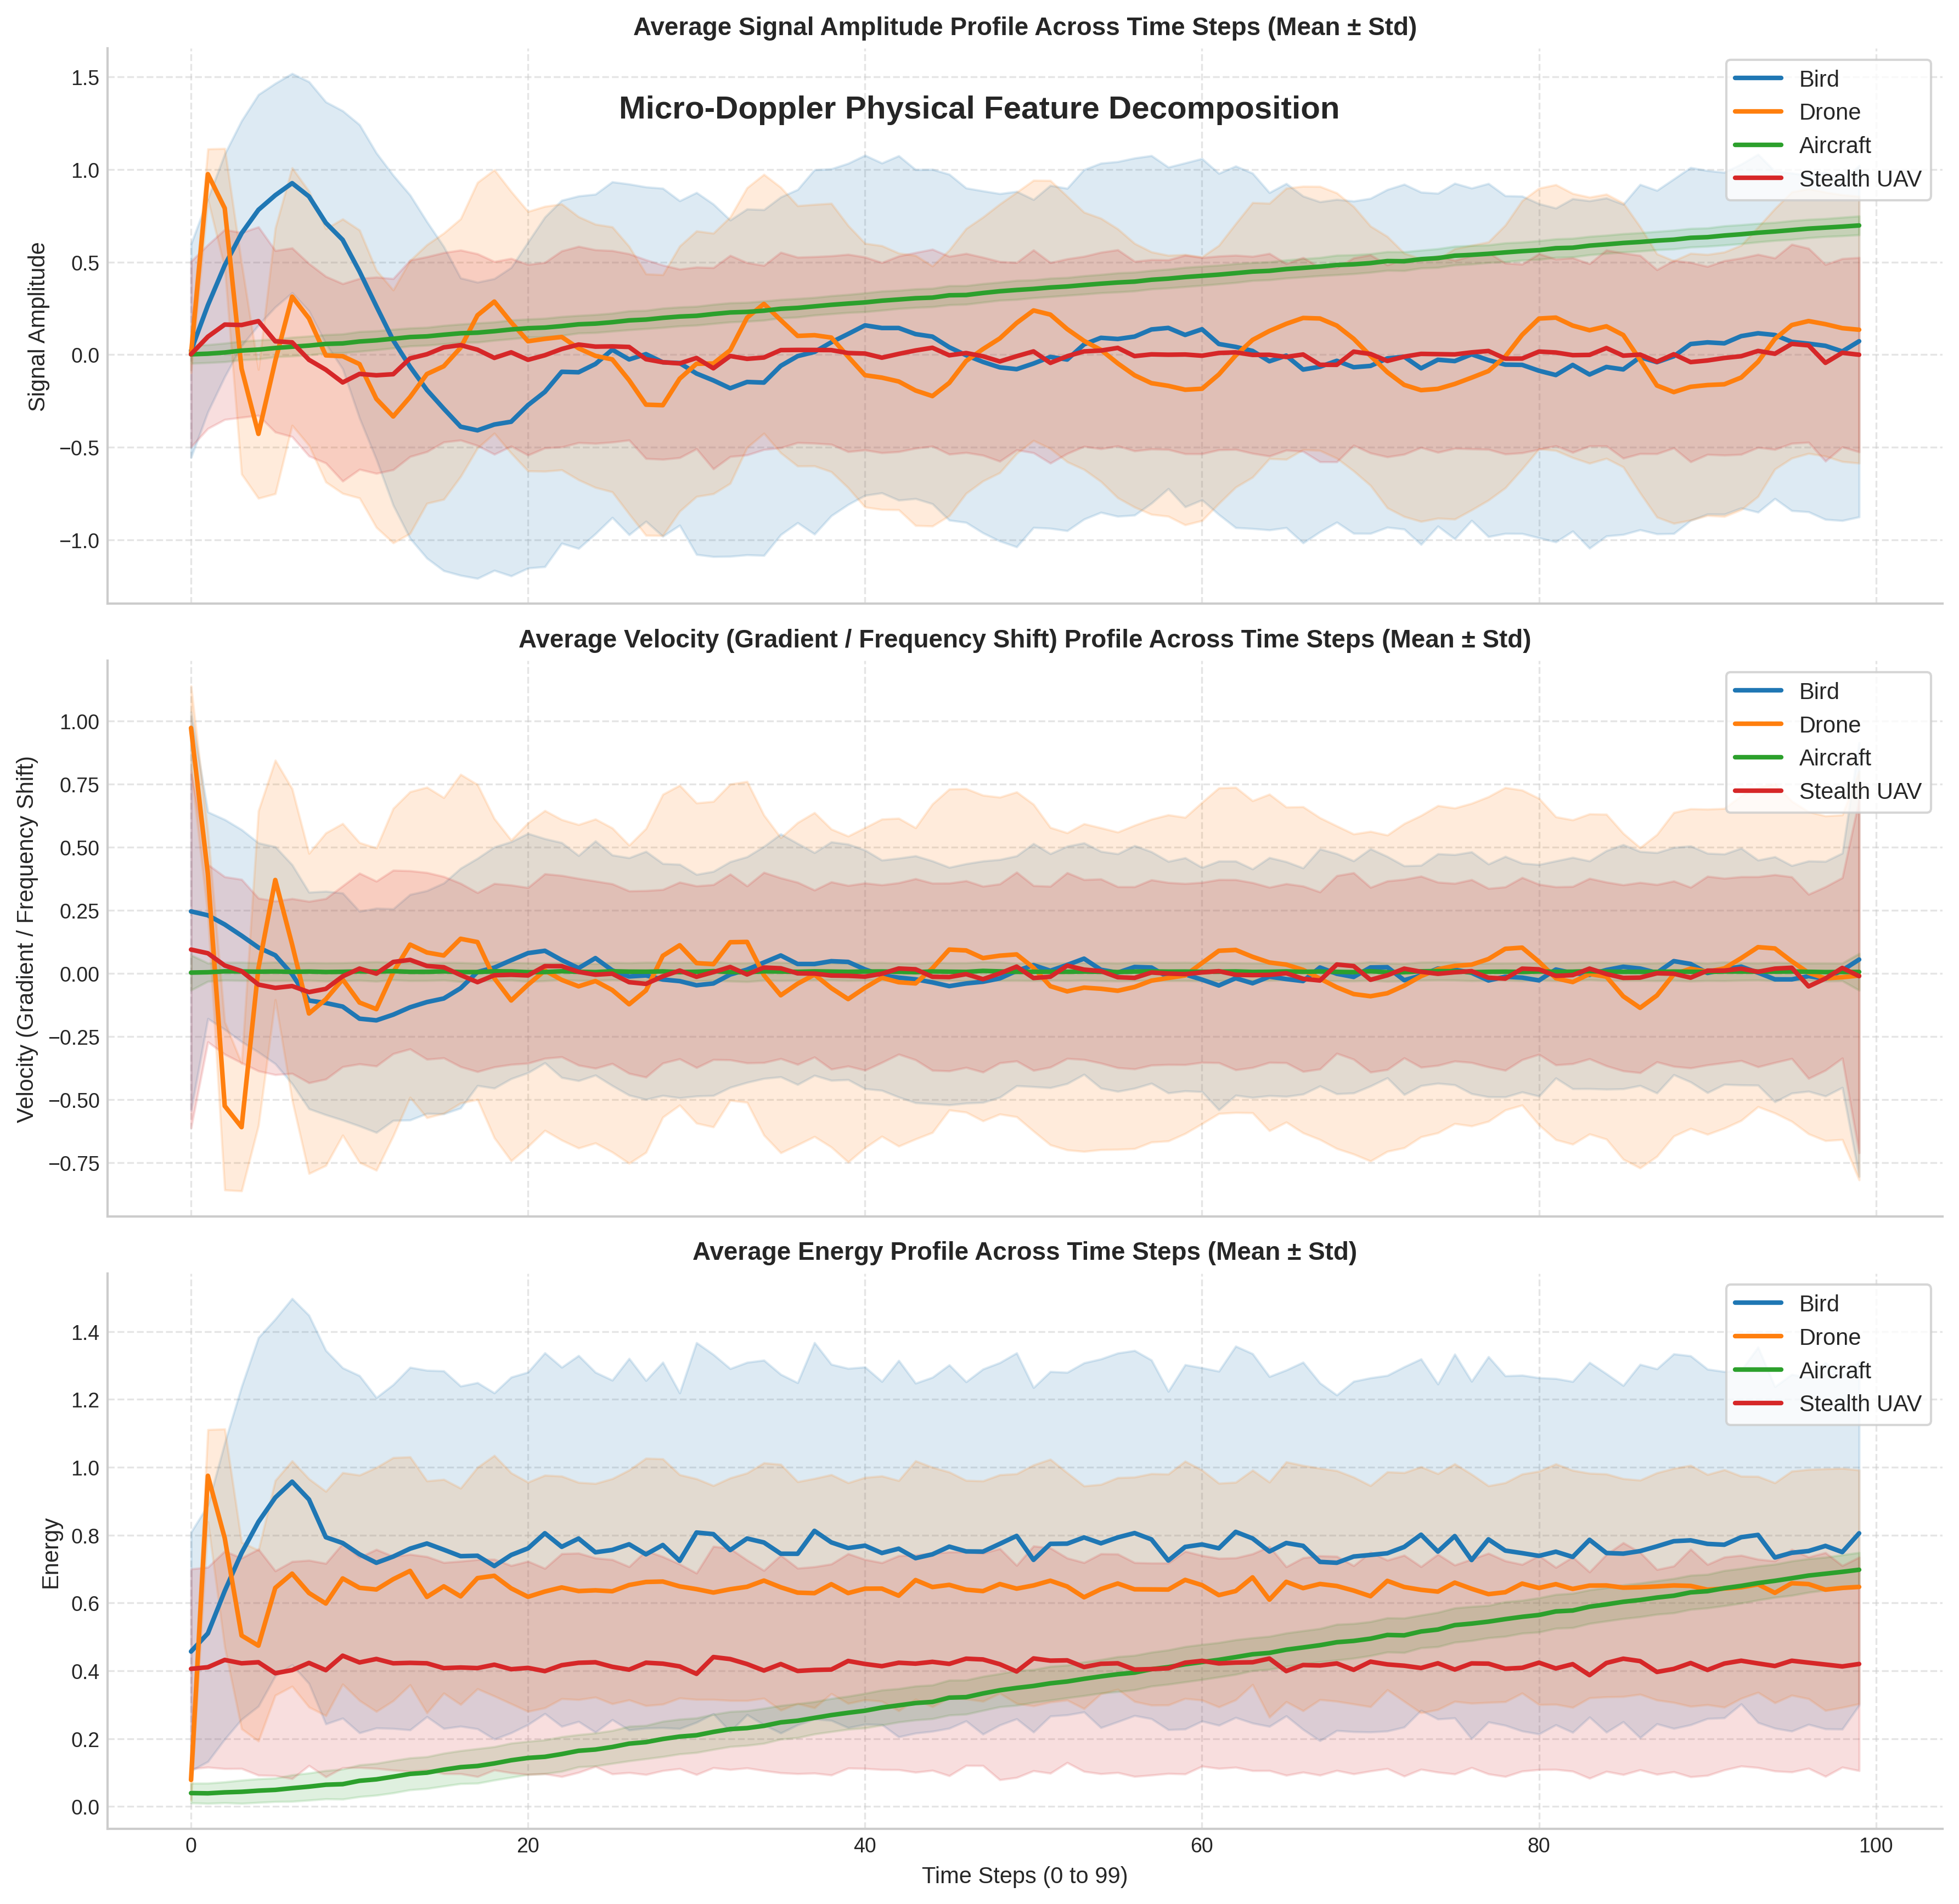

Physical feature profile plot successfully saved to outputs/figures/amplitude_velocity_energy_profiles.png


In [22]:
# --- STEP 4: PHYSICAL FEATURE PROFILES (AMPLITUDE, VELOCITY, ENERGY) ---
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("outputs/figures", exist_ok=True)

# 1. Extract feature columns and reshape data into 3D: (Samples, 100 timesteps, 3 features)
feature_cols = [str(i) for i in range(300)]
X = df[feature_cols].values
y = df['label'].values
X_3d = X.reshape(-1, 100, 3)

class_names = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
feature_names = ["Signal Amplitude", "Velocity (Gradient / Frequency Shift)", "Energy"]

# 2. Create a 3-panel vertical stack plot
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

for feat_idx in range(3):
    ax = axes[feat_idx]
    for label_id, name in class_names.items():
        class_data = X_3d[y == label_id]
        
        # Compute mean and standard deviation across samples for this feature
        mean_profile = class_data[:, :, feat_idx].mean(axis=0)
        std_profile = class_data[:, :, feat_idx].std(axis=0)
        
        # Plot mean line and shaded variance band
        ax.plot(mean_profile, color=colors[label_id], label=f"{name}", linewidth=2)
        ax.fill_between(range(100), mean_profile - std_profile, mean_profile + std_profile, 
                        color=colors[label_id], alpha=0.15)
        
    ax.set_title(f"Average {feature_names[feat_idx]} Profile Across Time Steps (Mean ± Std)", fontsize=11, fontweight='bold')
    ax.set_ylabel(feature_names[feat_idx], fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', frameon=True)

axes[2].set_xlabel("Time Steps (0 to 99)", fontsize=10)
plt.suptitle("Micro-Doppler Physical Feature Decomposition", fontsize=14, fontweight='bold', y=0.92)
plt.tight_layout()

# Save high-resolution asset
output_path = "outputs/figures/amplitude_velocity_energy_profiles.png"
plt.savefig(output_path, dpi=300)
plt.show()

print(f"Physical feature profile plot successfully saved to {output_path}")

In [ ]:
import numpy as np

# Extract features and reshape from (2800, 300) to (2800, 100 timesteps, 3 features)
feature_cols = [str(i) for i in range(300)]
X_3d = df[feature_cols].values.reshape(-1, 100, 3)
y = df['label'].values

class_names = {0: "Bird", 1: "Drone", 2: "Aircraft", 3: "Stealth UAV"}

for cls_id, name in class_names.items():
    cls_data = X_3d[y == cls_id]
    # Feature index 1 is Velocity (Gradient of signal / frequency shift)
    vel_std = cls_data[:, :, 1].std()
    mean_amp = cls_data[:, :, 0].mean()
    print(f"{name} -> Mean Amplitude: {mean_amp:.4f} | Velocity Fluctuation (Std): {vel_std:.4f}")

Bird -> Mean Amplitude: 0.0445 | Velocity Fluctuation (Std): 0.4741
Drone -> Mean Amplitude: 0.0164 | Velocity Fluctuation (Std): 0.6455
Aircraft -> Mean Amplitude: 0.3504 | Velocity Fluctuation (Std): 0.0365
Stealth UAV -> Mean Amplitude: 0.0024 | Velocity Fluctuation (Std): 0.3717
